# Random Forest classification using separate training samples for each date

This workflow uses a separate Random Forest model per date, so each model learns directly from the matching image conditions.

- **12 August 2023** uses `training_samples_2.shp`.
- **2 September 2023** uses `training_samples.shp`.

The class codes must mean the same thing in both files: 1 Vegetation, 2 Water, 3 Bare ground / mine surface. The comparison is then based on the two classified maps.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Forward-slash paths avoid Windows backslash escaping errors.
ROOT = Path("C:/Users/konil/Downloads/Technical Assignment_DS/Technical Assignment")
DATA = ROOT / "data"
COMPOSITES = DATA / "processed" / "composite"

BEFORE_RASTER = COMPOSITES / "comp_20230812.tif"
AFTER_RASTER = COMPOSITES / "comp_20230902.tif"
BEFORE_SAMPLES = DATA / "training_samples_2.shp"   # digitised on 12 August image
AFTER_SAMPLES = DATA / "training_samples.shp"      # digitised on 2 September image
OUT_DIR = DATA / "processed" / "random_forest"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_FIELD = "class_id"
CLASS_NAMES = {1: "Vegetation", 2: "Water", 3: "Bare ground / mine surface"}
MAX_PIXELS_PER_CLASS = 10000
RANDOM_STATE = 42

for p in [BEFORE_RASTER, AFTER_RASTER, BEFORE_SAMPLES, AFTER_SAMPLES]:
    assert p.exists(), f"Missing input: {p}"
print("Output folder:", OUT_DIR)


Output folder: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest


In [2]:
def read_samples(path, raster_path):
    samples = gpd.read_file(path)
    samples = samples[samples.geometry.notna() & ~samples.geometry.is_empty & samples.geometry.is_valid].copy()
    assert CLASS_FIELD in samples.columns, f"{path.name} has no {CLASS_FIELD}. Fields: {samples.columns.tolist()}"
    unknown = set(samples[CLASS_FIELD].dropna().unique()) - set(CLASS_NAMES)
    assert not unknown, f"Unknown class_id values in {path.name}: {unknown}"
    with rasterio.open(raster_path) as src:
        assert src.count == 3, f"{raster_path.name} must contain B02, B03, B04 only."
        samples = samples.to_crs(src.crs)
    print(f"{path.name}: {len(samples)} valid polygons")
    print(samples[CLASS_FIELD].value_counts().sort_index())
    return samples

before_samples = read_samples(BEFORE_SAMPLES, BEFORE_RASTER)
after_samples = read_samples(AFTER_SAMPLES, AFTER_RASTER)


training_samples_2.shp: 37 valid polygons
class_id
1    12
2     9
3    16
Name: count, dtype: int64
training_samples.shp: 65 valid polygons
class_id
1    29
2    19
3    17
Name: count, dtype: int64


In [3]:
def extract_training_pixels(raster_path, samples):
    rng = np.random.default_rng(RANDOM_STATE)
    feature_parts, label_parts = [], []
    with rasterio.open(raster_path) as src:
        for class_id in sorted(CLASS_NAMES):
            pieces = []
            for geom in samples.loc[samples[CLASS_FIELD] == class_id, "geometry"]:
                try:
                    clipped, _ = mask(src, [geom.__geo_interface__], crop=True, filled=False)
                except ValueError:  # polygon outside raster extent
                    continue
                values = np.moveaxis(clipped, 0, -1).reshape(-1, 3)
                valid = ~np.any(np.ma.getmaskarray(values), axis=1)
                values = values.data[valid].astype(np.float32)
                values = values[np.all(np.isfinite(values), axis=1) & np.all(values > 0, axis=1)]
                if len(values):
                    pieces.append(values)
            if not pieces:
                raise ValueError(f"No valid pixels for {CLASS_NAMES[class_id]} in {raster_path.name}")
            values = np.vstack(pieces)
            if len(values) > MAX_PIXELS_PER_CLASS:
                values = values[rng.choice(len(values), MAX_PIXELS_PER_CLASS, replace=False)]
            feature_parts.append(values)
            label_parts.append(np.full(len(values), class_id, dtype=np.uint8))
            print(f"{raster_path.stem} | {CLASS_NAMES[class_id]}: {len(values):,} pixels")
    return np.vstack(feature_parts), np.concatenate(label_parts)

def train_rf(raster_path, samples, date_label):
    X, y = extract_training_pixels(raster_path, samples)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    model = RandomForestClassifier(
        n_estimators=350, max_features="sqrt", min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\nInternal validation — {date_label}")
    print(classification_report(y_test, pred, labels=sorted(CLASS_NAMES), target_names=[CLASS_NAMES[c] for c in sorted(CLASS_NAMES)], digits=3))
    return model

rf_before = train_rf(BEFORE_RASTER, before_samples, "12 August 2023")
rf_after = train_rf(AFTER_RASTER, after_samples, "2 September 2023")
joblib.dump(rf_before, OUT_DIR / "rf_model_20230812.joblib")
joblib.dump(rf_after, OUT_DIR / "rf_model_20230902.joblib")


comp_20230812 | Vegetation: 10,000 pixels
comp_20230812 | Water: 10,000 pixels
comp_20230812 | Bare ground / mine surface: 10,000 pixels

Internal validation — 12 August 2023
                            precision    recall  f1-score   support

                Vegetation      0.998     1.000     0.999      2000
                     Water      1.000     0.998     0.999      2000
Bare ground / mine surface      0.999     0.999     0.999      2000

                  accuracy                          0.999      6000
                 macro avg      0.999     0.999     0.999      6000
              weighted avg      0.999     0.999     0.999      6000

comp_20230902 | Vegetation: 10,000 pixels
comp_20230902 | Water: 10,000 pixels
comp_20230902 | Bare ground / mine surface: 10,000 pixels

Internal validation — 2 September 2023
                            precision    recall  f1-score   support

                Vegetation      0.999     1.000     0.999      2000
                     Water      

['C:\\Users\\konil\\Downloads\\Technical Assignment_DS\\Technical Assignment\\data\\processed\\random_forest\\rf_model_20230902.joblib']

In [4]:
def classify(raster_path, model, output_path):
    with rasterio.open(raster_path) as src:
        image = src.read(masked=True)
        data = image.data.astype(np.float32)
        invalid = np.any(np.ma.getmaskarray(image), axis=0) | np.any(~np.isfinite(data), axis=0) | np.any(data <= 0, axis=0)
        h, w = src.height, src.width
        matrix = np.moveaxis(data, 0, -1).reshape(-1, 3)
        valid_idx = np.flatnonzero(~invalid.ravel())
        classes = np.zeros(h * w, dtype=np.uint8)
        for chunk in np.array_split(valid_idx, max(1, int(np.ceil(len(valid_idx) / 500_000)))):
            if len(chunk):
                classes[chunk] = model.predict(matrix[chunk]).astype(np.uint8)
        classes = classes.reshape(h, w)
        profile = src.profile.copy()
        profile.update(count=1, dtype="uint8", nodata=0, compress="lzw")
        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(classes, 1)
    return classes, src.transform

before_class, transform = classify(BEFORE_RASTER, rf_before, OUT_DIR / "rf_class_20230812.tif")
after_class, _ = classify(AFTER_RASTER, rf_after, OUT_DIR / "rf_class_20230902.tif")
print("Saved both classification rasters.")


Saved both classification rasters.


Saved: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest\rf_classification_comparison.png


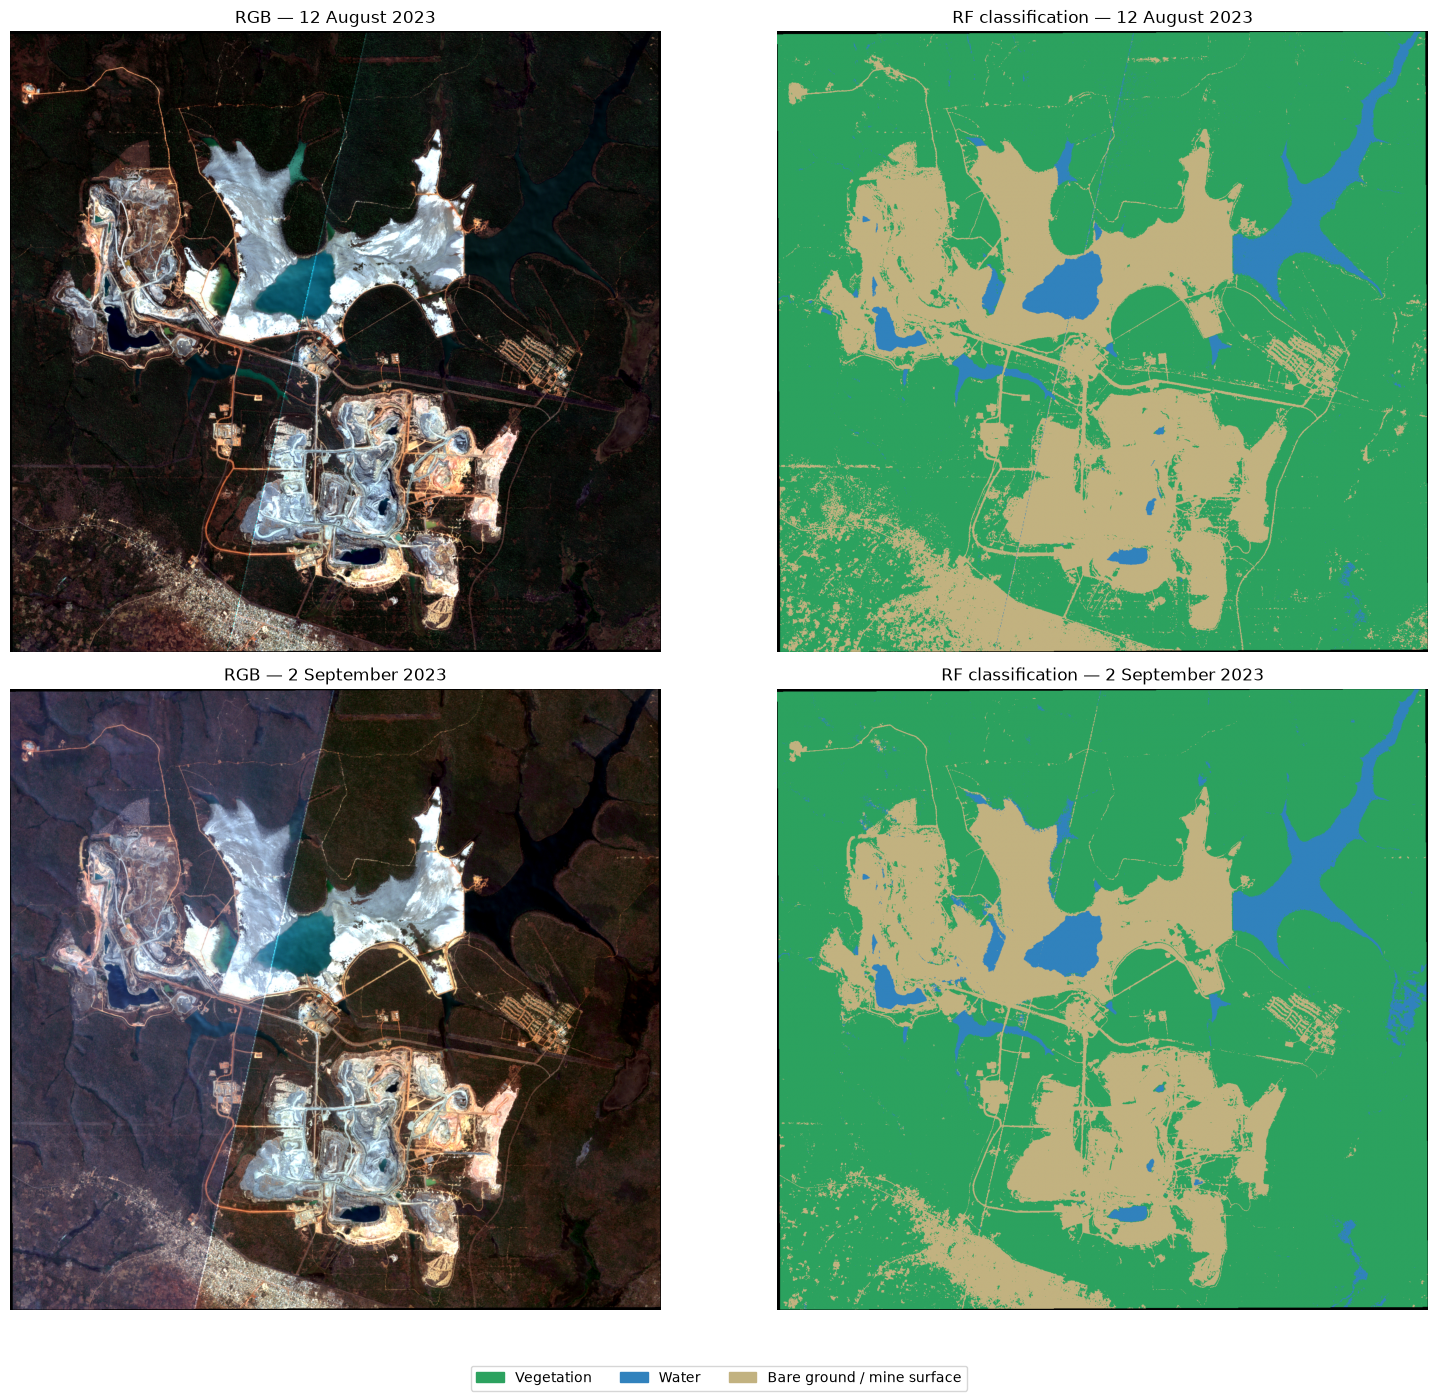

In [5]:
# Compare each RF result against its matching RGB image.
def rgb(path):
    with rasterio.open(path) as src:
        a = src.read([3, 2, 1]).astype(np.float32)  # B04, B03, B02
    invalid = np.any(a <= 0, axis=0)
    display = np.zeros_like(a, dtype=np.uint8)
    for i in range(3):
        lo, hi = np.percentile(a[i][~invalid], [2, 98])
        display[i] = np.clip((a[i] - lo) * 255 / max(hi - lo, 1e-6), 0, 255)
    return np.moveaxis(display, 0, -1)

cmap = ListedColormap(["#000000", "#2ca25f", "#3182bd", "#c2b280"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)
fig, ax = plt.subplots(2, 2, figsize=(16, 14))
ax[0, 0].imshow(rgb(BEFORE_RASTER)); ax[0, 0].set_title("RGB — 12 August 2023")
ax[0, 1].imshow(before_class, cmap=cmap, norm=norm); ax[0, 1].set_title("RF classification — 12 August 2023")
ax[1, 0].imshow(rgb(AFTER_RASTER)); ax[1, 0].set_title("RGB — 2 September 2023")
ax[1, 1].imshow(after_class, cmap=cmap, norm=norm); ax[1, 1].set_title("RF classification — 2 September 2023")
for a in ax.ravel(): a.axis("off")
fig.legend(handles=[Patch(color="#2ca25f", label="Vegetation"), Patch(color="#3182bd", label="Water"), Patch(color="#c2b280", label="Bare ground / mine surface")], loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
comparison_png = OUT_DIR / "rf_classification_comparison.png"
fig.savefig(comparison_png, dpi=200, bbox_inches="tight")
print("Saved:", comparison_png)
plt.show()


In [6]:
# Compute class-to-class transitions only after visually checking the two maps.
transition = np.where((before_class > 0) & (after_class > 0), before_class * 10 + after_class, 0).astype(np.uint8)
with rasterio.open(BEFORE_RASTER) as src:
    profile = src.profile.copy()
    profile.update(count=1, dtype="uint8", nodata=0, compress="lzw")
    with rasterio.open(OUT_DIR / "rf_transition_20230812_20230902.tif", "w", **profile) as dst:
        dst.write(transition, 1)

pixel_area_ha = abs(transform.a * transform.e) / 10000
rows=[]
for start in sorted(CLASS_NAMES):
    for end in sorted(CLASS_NAMES):
        code = start * 10 + end
        rows.append({"code": code, "from": CLASS_NAMES[start], "to": CLASS_NAMES[end], "area_ha": int((transition == code).sum()) * pixel_area_ha})
summary = pd.DataFrame(rows).sort_values("area_ha", ascending=False)
summary.to_csv(OUT_DIR / "rf_transition_area_ha.csv", index=False)
print(summary.to_string(index=False, formatters={"area_ha":"{:.2f}".format}))
print("Codes: 13 = Vegetation → Bare ground/mine; 12 = Vegetation → Water; 32 = Bare ground/mine → Water.")


 code                       from                         to  area_ha
   11                 Vegetation                 Vegetation 17396.73
   33 Bare ground / mine surface Bare ground / mine surface  6132.17
   31 Bare ground / mine surface                 Vegetation  1322.46
   22                      Water                      Water  1097.94
   13                 Vegetation Bare ground / mine surface   197.98
   12                 Vegetation                      Water   189.69
   21                      Water                 Vegetation    67.99
   23                      Water Bare ground / mine surface    31.24
   32 Bare ground / mine surface                      Water    20.92
Codes: 13 = Vegetation → Bare ground/mine; 12 = Vegetation → Water; 32 = Bare ground/mine → Water.


## Interpretation boundary

The two models are trained separately because each uses samples from its own date. This avoids forcing 12 August reflectance to match 2 September reflectance. The class codes have the same meaning across the two outputs, so the transition map can support visual screening. Check candidate transitions against both RGB images before reporting clearing, new water, or bare-ground expansion as confirmed.


Classified area by date (hectares)


date,2023-08-12,2023-09-02
class,,
Bare ground / mine surface,7475.55,6361.39
Vegetation,17784.40,18787.18
Water,1197.17,1308.55


Candidate class transitions (hectares)


,code,transition,area_ha
6,31,Bare ground / mine surface → Vegetation,1322.46
2,13,Vegetation → Bare ground / mine surface,197.98
1,12,Vegetation → Water,189.69
3,21,Water → Vegetation,67.99
5,23,Water → Bare ground / mine surface,31.24
7,32,Bare ground / mine surface → Water,20.92


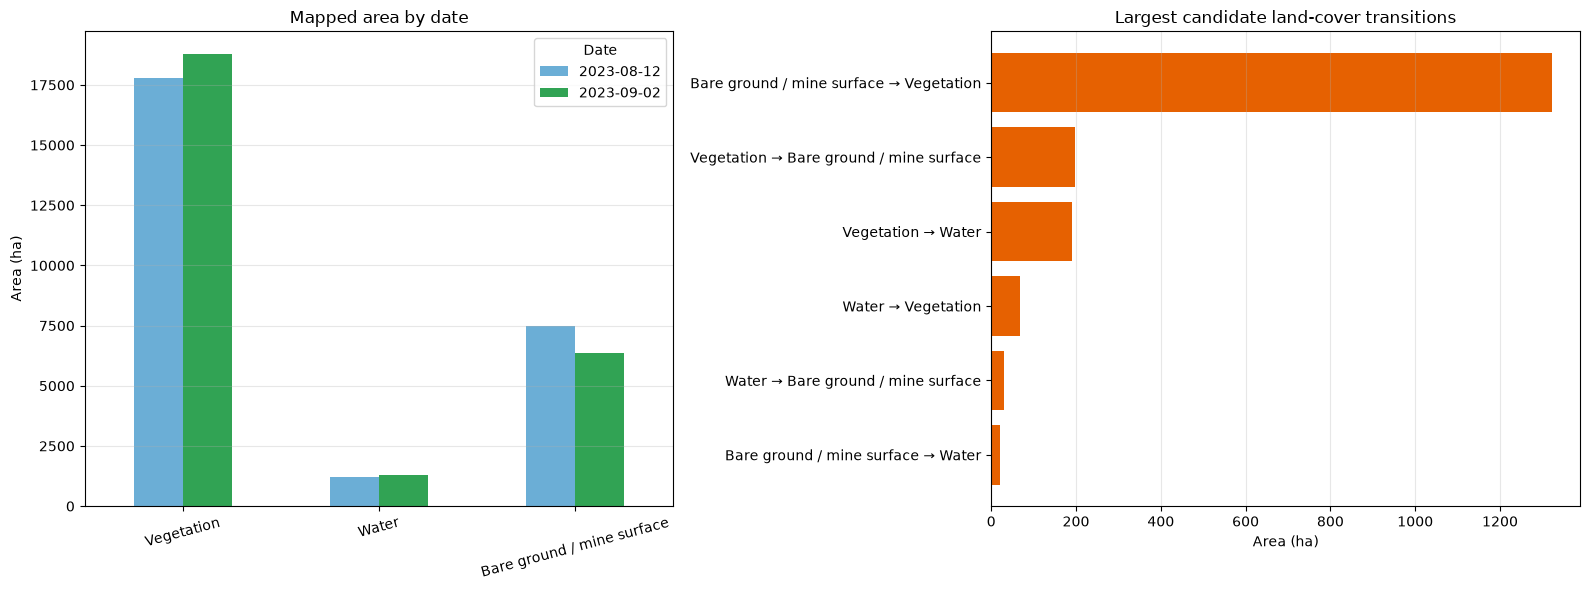

Saved class-area table: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest\rf_class_area_by_date.csv
Saved transition table: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest\rf_change_transition_area_ha.csv
Saved chart: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest\rf_area_and_transition_charts.png


In [7]:
# Area summary and charts for both classification dates.
pixel_area_ha = abs(transform.a * transform.e) / 10000

# 1. Area of each mapped class on each date
area_rows = []

for class_id, class_name in CLASS_NAMES.items():
    for date_label, classified_map in [
        ("2023-08-12", before_class),
        ("2023-09-02", after_class),
    ]:
        pixel_count = int((classified_map == class_id).sum())
        area_rows.append({
            "class_id": class_id,
            "class": class_name,
            "date": date_label,
            "pixels": pixel_count,
            "area_ha": pixel_count * pixel_area_ha,
        })

class_area = pd.DataFrame(area_rows)
class_area.to_csv(OUT_DIR / "rf_class_area_by_date.csv", index=False)

print("Classified area by date (hectares)")
display(
    class_area.pivot(
        index="class",
        columns="date",
        values="area_ha"
    ).round(2)
)

# 2. Keep only actual class transitions, excluding unchanged classes
change_summary = summary[summary["from"] != summary["to"]].copy()
change_summary["transition"] = (
    change_summary["from"] + " → " + change_summary["to"]
)
change_summary = change_summary.sort_values("area_ha", ascending=False)

change_summary.to_csv(
    OUT_DIR / "rf_change_transition_area_ha.csv",
    index=False
)

print("Candidate class transitions (hectares)")
display(
    change_summary[
        ["code", "transition", "area_ha"]
    ].round({"area_ha": 2})
)

# 3. Charts
pivot_area = class_area.pivot(
    index="class",
    columns="date",
    values="area_ha"
).reindex(list(CLASS_NAMES.values()))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pivot_area.plot(
    kind="bar",
    ax=axes[0],
    color=["#6baed6", "#31a354"]
)
axes[0].set_title("Mapped area by date")
axes[0].set_ylabel("Area (ha)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Date")
axes[0].grid(axis="y", alpha=0.3)

top_changes = change_summary.head(6).sort_values("area_ha")
axes[1].barh(
    top_changes["transition"],
    top_changes["area_ha"],
    color="#e66101"
)
axes[1].set_title("Largest candidate land-cover transitions")
axes[1].set_xlabel("Area (ha)")
axes[1].set_ylabel("")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()

chart_path = OUT_DIR / "rf_area_and_transition_charts.png"
plt.savefig(chart_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved class-area table:", OUT_DIR / "rf_class_area_by_date.csv")
print("Saved transition table:", OUT_DIR / "rf_change_transition_area_ha.csv")
print("Saved chart:", chart_path)

Displayed transitions after artefact filtering


,transition_code,transition,displayed_pixels,displayed_area_ha
1,13,Vegetation → Bare ground / mine surface,7017,70.17
3,23,Water → Bare ground / mine surface,1453,14.53
0,12,Vegetation → Water,24,0.24
2,21,Water → Vegetation,0,0.00
4,31,Bare ground / mine surface → Vegetation,0,0.00
5,32,Bare ground / mine surface → Water,0,0.00


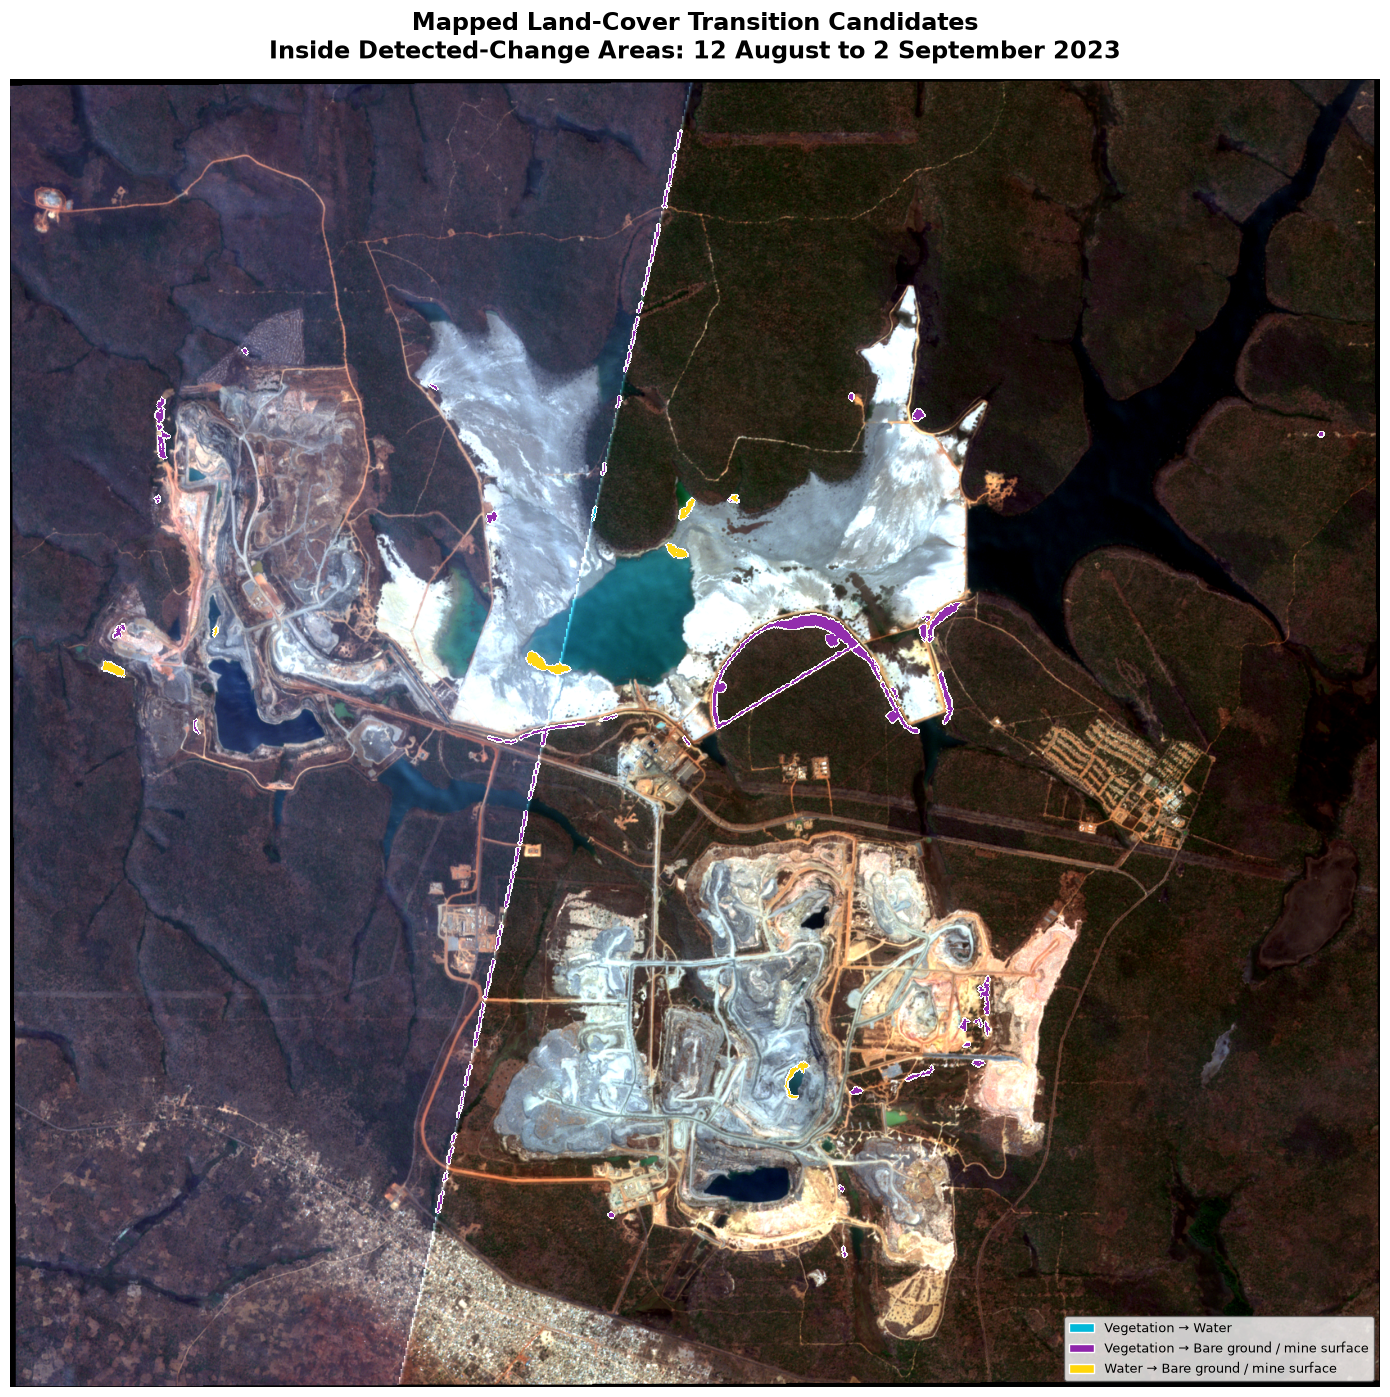

Saved: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\random_forest\rf_clean_class_transition_map.png


In [15]:
# Clean class-transition map inside ESD detected-change areas.
# This display filter removes:
# 1. Small fragmented patches
# 2. Long and narrow seam-like artefacts

from scipy.ndimage import binary_dilation, label
from matplotlib.patches import Patch

MIN_DISPLAY_PATCH_HA = 0.20
MIN_SEAM_LENGTH_M = 700
MAX_SEAM_WIDTH_M = 150
MIN_SEAM_ASPECT_RATIO = 6

def rgb_for_map(path):
    """Create B04-B03-B02 RGB for map display."""
    with rasterio.open(path) as src:
        raw = src.read([3, 2, 1]).astype(np.float32)

    valid = np.all(raw > 0, axis=0)
    output = np.zeros_like(raw, dtype=np.uint8)

    for band in range(3):
        values = raw[band][valid]
        low, high = np.percentile(values, [2, 98])

        output[band] = np.clip(
            (raw[band] - low) / max(high - low, 1e-6) * 255,
            0,
            255
        ).astype(np.uint8)

    return np.moveaxis(output, 0, -1)


def clean_transition_mask(binary_mask):
    """
    Remove small patches and long narrow artefacts.
    This affects visual presentation only, not RF or ESD source outputs.
    """
    min_pixels = int(np.ceil(MIN_DISPLAY_PATCH_HA / pixel_area_ha))

    labelled, patch_count = label(
        binary_mask,
        structure=np.ones((3, 3), dtype=np.uint8)
    )

    cleaned = np.zeros_like(binary_mask, dtype=bool)

    for patch_id in range(1, patch_count + 1):
        patch = labelled == patch_id
        pixel_count = int(patch.sum())

        if pixel_count < min_pixels:
            continue

        rows, cols = np.where(patch)

        height_pixels = rows.max() - rows.min() + 1
        width_pixels = cols.max() - cols.min() + 1

        long_axis_m = max(height_pixels, width_pixels) * 10
        short_axis_m = min(height_pixels, width_pixels) * 10

        aspect_ratio = long_axis_m / max(short_axis_m, 1)

        # Remove image seams: long, thin, linear components.
        is_seam_artefact = (
            long_axis_m >= MIN_SEAM_LENGTH_M and
            short_axis_m <= MAX_SEAM_WIDTH_M and
            aspect_ratio >= MIN_SEAM_ASPECT_RATIO
        )

        if not is_seam_artefact:
            cleaned[patch] = True

    return cleaned


transition_style = {
    12: {"label": "Vegetation → Water", "colour": "#00B8D9"},
    13: {"label": "Vegetation → Bare ground / mine surface", "colour": "#8E24AA"},
    21: {"label": "Water → Vegetation", "colour": "#00A65A"},
    23: {"label": "Water → Bare ground / mine surface", "colour": "#FFD60A"},
    31: {"label": "Bare ground / mine surface → Vegetation", "colour": "#76FF03"},
    32: {"label": "Bare ground / mine surface → Water", "colour": "#1565FF"},
}

cleaned_transitions = {}
summary_rows = []

for code, info in transition_style.items():
    raw_mask = interpreted_change == code
    cleaned_mask = clean_transition_mask(raw_mask)

    cleaned_transitions[code] = cleaned_mask

    pixel_count = int(cleaned_mask.sum())

    summary_rows.append({
        "transition_code": code,
        "transition": info["label"],
        "displayed_pixels": pixel_count,
        "displayed_area_ha": pixel_count * pixel_area_ha,
    })

cleaned_transition_summary = pd.DataFrame(summary_rows)

print("Displayed transitions after artefact filtering")
display(
    cleaned_transition_summary
    .sort_values("displayed_area_ha", ascending=False)
    .round({"displayed_area_ha": 2})
)

background = rgb_for_map(AFTER_RASTER)

fig, ax = plt.subplots(figsize=(14, 14), facecolor="white")
ax.imshow(background)

legend_items = []

for code, info in transition_style.items():
    change_mask = cleaned_transitions[code]

    if not np.any(change_mask):
        continue

    # White halo improves visibility over the RGB imagery.
    halo = binary_dilation(change_mask, iterations=2)

    ax.imshow(
        np.where(halo, 1, np.nan),
        cmap=ListedColormap(["#FFFFFF"]),
        alpha=0.95,
        interpolation="none"
    )

    ax.imshow(
        np.where(change_mask, 1, np.nan),
        cmap=ListedColormap([info["colour"]]),
        alpha=0.96,
        interpolation="none"
    )

    legend_items.append(
        Patch(
            facecolor=info["colour"],
            edgecolor="white",
            label=info["label"]
        )
    )

ax.set_title(
    "Mapped Land-Cover Transition Candidates\n"
    "Inside Detected-Change Areas: 12 August to 2 September 2023",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax.axis("off")

ax.legend(
    handles=legend_items,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#555555",
    fontsize=9
)

plt.tight_layout()

clean_map_path = OUT_DIR / "rf_clean_class_transition_map.png"
plt.savefig(clean_map_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", clean_map_path)